# A planet in a gap between inclined rings

A [`MultipoleDisk`](api/models/classes/multipole_disk.md) describes a disk, ring or halo by a radial brightness profile $I_0(r)$ in the plane of the disk, tilted by `inc` and rotated by `pa`. Its visibility is the Hankel transform of the profile, normalized to one at zero baseline,

$$
V(q) = \frac{\int I_0(r)\, J_0(2\pi q' r)\, r\,\mathrm{d}r}{\int I_0(r)\, r\,\mathrm{d}r},
$$

with $q'$ the baseline's spatial frequency in the disk plane. The profile can be a parametric ring or a free function: a Gaussian process, whose log-intensity at $n$ radial nodes is $\sigma L z$, with $LL^\top$ a Matérn correlation matrix of length $\ell$ and $z \sim \mathcal N(0, I)$ the free parameters, so the intensity is positive for any $z$. A disk can also be lopsided (azimuthal harmonics) and chromatic (a spectral index, $I(r,\lambda) = I_0(r)(\lambda/\lambda_0)^{\alpha(r)}$).

Here we simulate a star with three inclined rings and a planet in a gap, observed with VLTI-like closure phases and squared visibilities. We fit the data twice, with the family that made them and with one Gaussian-process `MultipoleDisk`, and compare the two. You will see how to build a `MultipoleDisk` scene, how to fit a non-parametric profile, and what the data can and cannot tell the Gaussian process. Both fits are maximum a posteriori (MAP) with a Laplace approximation, with no sampling. On this page the long plotting code is folded; the notebook has it all.

## The scene and the data

The star is a 6000 K blackbody point source, and every other flux is relative to it at 3 microns. The three rings are coplanar `MultipoleDisk`s with `GaussianRing` profiles at 4.5, 10 and 21.5 mas (widths $\sigma$ of 1.3, 1.5 and 2.4 mas) and blackbody colours of 1500, 900 and 600 K; the outermost has a first-order harmonic, which makes it lopsided. A 1000 K planet sits in the gap between the second and third rings. Ring radii are measured in the disk plane, so we put the planet on the projected major axis, where sky and plane distances agree, at 14.4 mas from the star: $(\Delta\alpha, \Delta\delta) = (-7.2, -12.47)$ mas. The cell prints a deprojection check of this. The `scene` function gives one `inc` and `pa` to all the rings, and the fits below reuse it.

The data mimic a low-resolution L-band run with the four unit telescopes: nine channels from 2.4 to 3.6 microns and seven hour angles, giving 378 squared visibilities (error 0.01) and 252 closure phases (error 0.5°), or 567 independent data once the closure phases' correlations are counted. The longest baseline gives a half-fringe $\lambda/2B$ of 2 to 3 mas, so the rings' widths (FWHM 3.1, 3.5 and 5.7 mas) are at or above the resolution, and structure much finer than that is not measured. The image shows the truth at 3 microns, East to the left, with the star saturated to show the outer ring and the beam in the corner.

planet: sky separation 14.40 mas, disk-plane radius 14.40 mas (rings at 4.5, 10.0, 21.5 mas)


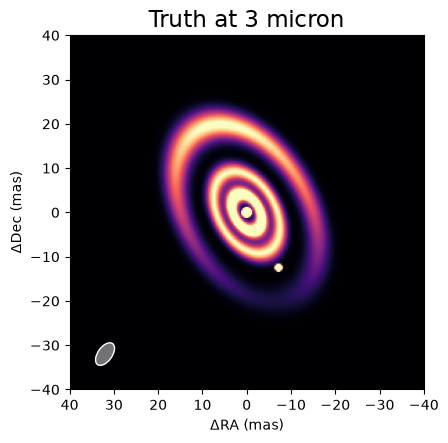

In [1]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()
)
sys.path.insert(0, str(root / "src"))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist

from virgil import (
    BlackBody, GaussianRing, Harmonics, PointSource, MultipoleDisk,
    MultipoleKernel, RadialGP, RadialGPFunction, System, fit, gp_priors,
)
from virgil.coverage import vlti_oidata
from virgil.imaging import beam, log_evidence
from virgil.inference import laplace_cov
from virgil.likelihood import whitened_residuals
from virgil.priors import IsotropicInclination
from virgil.plotting import plot_model, plot_residual_map

W0 = 3.0e-6  # reference wavelength, m


def scene(inc, pa, r1, s1, f1, t1, r2, s2, f2, t2, r3, s3, f3, t3,
          h_re, h_im, dra, ddec, fp, tp):
    """Star, three coplanar rings and a planet; one inc and pa for the rings."""
    def ring(radius, sigma, flux, temp, **kw):
        return MultipoleDisk(GaussianRing(radius, sigma), inc=inc, pa=pa, n_r=48,
                         flux=BlackBody(flux, temp, W0), **kw)
    return System(
        star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
        ring1=ring(r1, s1, f1, t1),
        ring2=ring(r2, s2, f2, t2),
        ring3=ring(r3, s3, f3, t3, harmonics=Harmonics(re=h_re, im=h_im)),
        planet=PointSource(dra=dra, ddec=ddec, flux=BlackBody(fp, tp, W0)),
    )


truth = dict(inc=50.0, pa=30.0, r1=4.5, s1=1.3, f1=0.15, t1=1500.0,
             r2=10.0, s2=1.5, f2=0.25, t2=900.0, r3=21.5, s3=2.4, f3=0.5,
             t3=600.0, h_re=0.5, h_im=0.2, dra=-7.2, ddec=-12.471, fp=0.04,
             tp=1000.0)
truth_model = scene(**truth)


def plane_radius(dra, ddec, inc, pa):
    """Disk-plane radius of a sky offset: rotate to the major/minor axes, de-foreshorten the minor."""
    pa_r = np.radians(pa)
    major = dra * np.sin(pa_r) + ddec * np.cos(pa_r)
    minor = dra * np.cos(pa_r) - ddec * np.sin(pa_r)
    return float(np.hypot(major, minor / np.cos(np.radians(inc))))


print("planet: sky separation "
      f"{np.hypot(truth['dra'], truth['ddec']):.2f} mas, disk-plane radius "
      f"{plane_radius(truth['dra'], truth['ddec'], truth['inc'], truth['pa']):.2f} mas "
      f"(rings at {truth['r1']}, {truth['r2']}, {truth['r3']} mas)")
template = vlti_oidata(
    wavelengths_m=np.linspace(2.4e-6, 3.6e-6, 9),
    hour_angles_h=(-3, -2, -1, 0, 1, 2, 3),
    sigma_v2=0.01, sigma_cp_deg=0.5,
)
data = template.with_model(truth_model, key=jax.random.PRNGKey(0))
fig, ax = plt.subplots(figsize=(5, 4.6))
FOV = 80  # mas
plot_model(truth_model, fov_mas=FOV, npix=256, ax=ax, saturate=0.99,
           beam=beam(data), title="Truth at 3 micron")
plt.show()


## The parametric fit

First we fit the family that made the data: 20 parameters in all, namely the shared geometry, a radius, width, flux and temperature for each ring, the outer harmonic's two components, and the planet's offset, flux and temperature. The priors are the invariant ones: uniform in $\cos i$ for the inclination (`IsotropicInclination`), uniform for angles and locations, and log-uniform for scales. We start 5 percent from the truth, as a local optimizer needs, run `fit` (Levenberg–Marquardt) to the MAP, and take the Laplace covariance with `laplace_cov`.

The printed $\chi^2/N$ is on the quoted errors with no rescaling, and is close to 1, as it should be for the family that made the data. The table gives the truth, the MAP and the Laplace standard deviation of every parameter. The widths are the hardest, because the narrowest ring is only a little wider than the half-fringe, and a Gaussian approximation is poor for a scale pressed against its prior edge, which matters for the evidence below.

In [2]:
priors = dict(inc=IsotropicInclination(0, 85), pa=dist.Uniform(-90, 90),
              h_re=dist.Uniform(-1, 1), h_im=dist.Uniform(-1, 1),
              dra=dist.Uniform(-20, 20), ddec=dist.Uniform(-20, 20),
              fp=dist.LogUniform(0.003, 0.3), tp=dist.LogUniform(300, 3000))
for i in (1, 2, 3):
    priors |= {f"r{i}": dist.LogUniform(0.5, 40), f"s{i}": dist.LogUniform(0.1, 6),
               f"f{i}": dist.LogUniform(0.01, 2),
               f"t{i}": dist.LogUniform(300, 3000)}
start = {k: v * (1 + 0.05 * (-1) ** i) for i, (k, v) in enumerate(truth.items())}
par = fit(scene, priors, data, init=start)
names = list(priors)
x_map = np.array([float(par.values[k]) for k in names])
sigma = np.sqrt(np.diag(np.asarray(laplace_cov(x_map, names, scene, data))))
print(f"chi2 = {par.info['chi2'][0]:.0f} for N = {par.info['ndata'][0]} "
      f"independent data (chi2/N = {par.info['chi2'][0] / par.info['ndata'][0]:.2f}), "
      f"converged: {par.info['converged']}")
print(f"{'':>6}{'truth':>9}{'MAP':>9}{'Laplace sd':>12}")
for k, x, s in zip(names, x_map, sigma):
    print(f"{k:>6}{truth[k]:9.3f}{x:9.3f}{s:12.3f}")


chi2 = 572 for N = 567 independent data (chi2/N = 1.01), converged: True
          truth      MAP  Laplace sd
   inc   50.000   50.108       0.205
    pa   30.000   29.968       0.277
  h_re    0.500    0.600       0.049
  h_im    0.200    0.229       0.021
   dra   -7.200   -7.254       0.026
  ddec  -12.471  -12.488       0.027
    fp    0.040    0.041       0.001
    tp 1000.000 1021.563      26.289
    r1    4.500    4.465       0.072
    s1    1.300    1.296       0.169
    f1    0.150    0.165       0.015
    t1 1500.000 1285.479      71.296
    r2   10.000    9.940       0.122
    s2    1.500    1.519       0.130
    f2    0.250    0.277       0.015
    t2  900.000  940.209      29.298
    r3   21.500   21.488       0.029
    s3    2.400    2.403       0.042
    f3    0.500    0.454       0.019
    t3  600.000  582.920       9.105


## The non-parametric fit

Now the model that does not know about rings. One `MultipoleDisk` has a `RadialGP` profile on 48 nodes between 2 and 30 mas, with a Matérn-3/2 length $\ell = 5$ mas and $\sigma = 2$ on $\ln I_0$. Its `Harmonics(degree=1, prior=MultipoleKernel(...))` has a first-order amplitude and phase that are Gaussian processes in radius, and its `spectral_index` is a `RadialGPFunction`. Limiting the harmonics to first order stops the disk absorbing the planet, a compact, strongly asymmetric source, so the planet keeps its parametric form with the star. `gp_priors` writes the standard-normal prior of every latent, and the geometry, total disk flux and planet start at the parametric MAP, with the geometry held there.

The hyperparameters are fixed by hand, not fitted. We set them from the scale of this scene, which a real analysis would not know: it would sample them, or compare evidences as in the next section. Here $\sigma = 2$ is of the order of the true profile's spread in $\ln I_0$ (about 1.6 between 2 and 30 mas), and the spectral index's $\sigma = 2.5$ covers the three blackbodies' slopes ($-1.7$, $0.35$ and $3.0$ at 3 microns). A Matérn length is not a feature width: a squared-exponential bump of the same curvature has width $\ell/\sqrt3$, so $\ell = 5$ mas is 2.9 mas, which smooths the inner rings (1.3 and 1.5 mas) rather than matching them. The inner edge is at 2 mas, the half-fringe, so the profile cannot hide light in an unresolved core that trades off against the star. The cell prints $\chi^2/N$ on the quoted errors, the planet's position and flux against the parametric fit and the truth, and the disk flux.

In [3]:
v = par.values
r_in, r_out = 2.0, 30.0
ell_gp = 5.0  # profile correlation length (mas); see the text
disk = MultipoleDisk(
    RadialGP(r_in, r_out, sigma=2.0, ell=ell_gp),
    harmonics=Harmonics(degree=1, prior=MultipoleKernel(
        ell_r=5.0, ell_theta=8.0, sigma=0.5, n=10, r_in=r_in, r_out=r_out)),
    spectral_index=RadialGPFunction(r_in, r_out, sigma=2.5, ell=4.0, n=22),
    wavel0=W0, inc=v["inc"], pa=v["pa"], n_r=48,
    flux=v["f1"] + v["f2"] + v["f3"],
)
gp = System(
    star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
    disk=disk,
    planet=PointSource(dra=v["dra"], ddec=v["ddec"],
                       flux=BlackBody(v["fp"], v["tp"], W0)),
)
gp_priors_ = gp_priors(gp) | {
    "disk.flux": dist.LogUniform(0.05, 5.0),
    "planet.dra": dist.Uniform(-20, 20), "planet.ddec": dist.Uniform(-20, 20),
    "planet.flux.ratio": dist.LogUniform(0.003, 0.3),
    "planet.flux.temperature": dist.LogUniform(300, 3000),
}
gpfit = fit(gp, gp_priors_, data)
gv = gpfit.values
true_disk_flux = truth["f1"] + truth["f2"] + truth["f3"]
print(f"chi2 = {gpfit.info['chi2'][0]:.0f} for N = {gpfit.info['ndata'][0]} "
      f"independent data (chi2/N = {gpfit.info['chi2'][0] / gpfit.info['ndata'][0]:.2f}), "
      f"converged: {gpfit.info['converged']}, {gpfit.info['steps']} steps")
print(f"planet offset (dra, ddec) = ({gv['planet.dra']:.2f}, {gv['planet.ddec']:.2f}) mas "
      f"(parametric: {v['dra']:.2f}, {v['ddec']:.2f}; "
      f"truth {truth['dra']:.2f}, {truth['ddec']:.2f})")
print(f"planet flux at 3 micron = {gv['planet.flux.ratio']:.3f} of the star "
      f"(parametric: {v['fp']:.3f}; truth {truth['fp']:.3f})")
print(f"disk flux at 3 micron = {gv['disk.flux']:.2f} "
      f"(parametric rings: {v['f1'] + v['f2'] + v['f3']:.2f}; truth {true_disk_flux:.2f})")


chi2 = 648 for N = 567 independent data (chi2/N = 1.14), converged: True, 64 steps
planet offset (dra, ddec) = (-7.25, -12.50) mas (parametric: -7.25, -12.49; truth -7.20, -12.47)
planet flux at 3 micron = 0.041 of the star (parametric: 0.041; truth 0.040)
disk flux at 3 micron = 0.89 (parametric rings: 0.90; truth 0.90)


## The evidence, parametric against Gaussian process

To compare the two fits we use Laplace evidences. For the parametric model, $\log Z \approx -\tfrac12\chi^2 + \log\pi(\hat\theta) + \tfrac d2\log 2\pi + \tfrac12\log\det\Sigma$, and `log_evidence` gives the equivalent for the Gaussian process's latents, $-\tfrac12\chi^2 - \tfrac12|z|^2 - \tfrac12\log\det(I + J^TJ)$. The two share a normalization, so only their difference means anything, and even that is only indicative, not a calibrated Bayes factor. The Gaussian-process value holds the geometry (tuned on these data), the planet and the disk flux at their MAP values with no Occam factor, which favours the Gaussian process; the parametric family contains the truth, which no real analysis can assume, and marginalizes all 20 parameters, which favours the parametric model; and the Laplace approximation is rough for the width pressed against its prior edge.

We also refit the Gaussian process with a profile length of 2 mas instead of 5. That compares two fits with the same held parameters, the cleaner use of the evidence, as in MacKay's choice of a hyperparameter.

In [4]:
gpm = gpfit.model
# Laplace evidence of the parametric fit: log L + log prior + (d/2) log 2 pi
# + (1/2) log det Sigma, in the same data normalization as log_evidence.
cov = np.asarray(laplace_cov(x_map, names, scene, data))
chi2_par = float(np.sum(np.asarray(whitened_residuals(par.model, data)) ** 2))
log_prior = sum(float(priors[k].log_prob(par.values[k])) for k in names)
logz_par = (-0.5 * chi2_par + log_prior + 0.5 * len(names) * np.log(2 * np.pi)
            + 0.5 * np.linalg.slogdet(cov)[1])
ell_alt = 2.0
logz = {}
for ell in (ell_gp, ell_alt):
    f = gpfit if ell == ell_gp else fit(gp.set("disk.profile.ell", ell), gp_priors_, data)
    logz[ell] = float(log_evidence(f, data, path="disk"))
print(f"parametric (20 parameters, Laplace-marginalized): log Z = {logz_par:8.1f}")
for ell, z in logz.items():
    print(f"GP (other parameters at MAP), profile length scale {ell:4.2f} mas: log Z = {z:8.1f}"
          + ("  (used below)" if ell == ell_gp else ""))
print(f"log Z(ell = {ell_gp:g}) - log Z(ell = {ell_alt:g}) = {logz[ell_gp] - logz[ell_alt]:.1f}; "
      f"parametric - GP = {logz_par - logz[ell_gp]:.1f}")


parametric (20 parameters, Laplace-marginalized): log Z =   -381.7
GP (other parameters at MAP), profile length scale 5.00 mas: log Z =   -414.4  (used below)
GP (other parameters at MAP), profile length scale 2.00 mas: log Z =   -412.7
log Z(ell = 5) - log Z(ell = 2) = -1.6; parametric - GP = 32.6


## What the data taught the Gaussian process

The parametric model is told where the rings are, so its $\log Z$ is the higher of the two. The more interesting number is the difference between the two length scales, printed above, which is only a couple of nat. That is within what a Laplace evidence conditional on the fitted parameters can support, so **the data do not measure the profile's length scale**: it is a prior choice, not a result, and the posterior's fine structure is set by it wherever the data are silent. Neither length matches the rings: $\ell/\sqrt3$ is 2.9 mas and 1.2 mas against widths of 1.3, 1.5 and 2.4 mas. Nor can either fit resolve scales below the half-fringe of 2 to 3 mas, so any structure the Gaussian-process band shows there, and its behaviour at the inner edge, where the profile trades light with the star, is the prior. And the hyperparameters came from the truth's scale, which a real analysis cannot do: a prior much rougher than the scene, such as $\sigma = 3$ with $\ell = 1.5$ mas, has a typical slope of $\ln I_0$ of $\sqrt3\sigma/\ell \approx 3.5$ nat/mas, against about 0.8 nat/mas rms for the truth.

The panels compare the prior of the profile and of the spectral index (16 to 84 percent of draws at the fixed hyperparameters) with draws from the Laplace posterior of the latents, $\mathcal N(z_0, (I + J^TJ)^{-1})$, the approximation the evidence uses. Only the latents vary, so the bands are narrower than the full posterior.

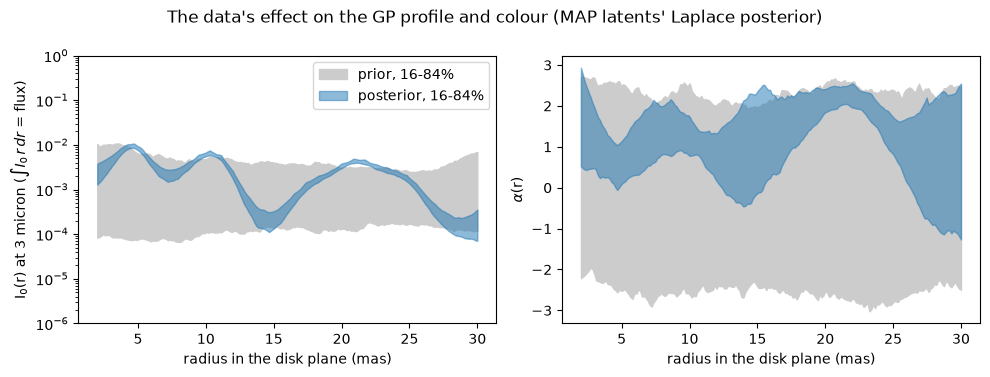

In [5]:
latents = ["disk.profile.z", "disk.harmonics.z", "disk.spectral_index.z"]
z0 = [np.asarray(gpm.get(p)) for p in latents]
flat0 = jnp.concatenate([jnp.ravel(z) for z in z0])


def residuals(flat):
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    return whitened_residuals(m, data)


# Laplace posterior of the latents, N(z0, (I + J^T J)^-1), as log_evidence uses
jac = np.asarray(jax.jacfwd(residuals)(flat0))
chol = np.linalg.cholesky(np.linalg.inv(np.eye(flat0.size) + jac.T @ jac))
rng = np.random.default_rng(0)
draws = np.asarray(flat0) + rng.standard_normal((200, flat0.size)) @ chol.T

rg = np.linspace(r_in, r_out, 200)


def profile_alpha(flat):
    """Surface brightness (unit integral times the disk flux), alpha(r), |I_1|."""
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    i0 = m.disk.profile.intensity(rg, 0.1)
    i0 = i0 / jnp.trapezoid(i0 * rg, rg) * m.disk.flux
    return (i0, m.disk.spectral_index(rg),
            jnp.abs(m.disk.harmonics.image_harmonics(rg)[1]))


post_i0, post_al, post_h1 = (
    np.asarray(x) for x in jax.vmap(profile_alpha)(jnp.asarray(draws))
)
key = jax.random.PRNGKey(1)
prior_i0 = np.asarray(gpm.disk.profile.draws(key, 200, r=rg, positive=True))
prior_i0 = prior_i0 / np.trapezoid(prior_i0 * rg, rg, axis=1)[:, None] * float(gpm.disk.flux)
prior_al = np.asarray(gpm.disk.spectral_index.draws(key, 200, r=rg))
band = lambda x: np.percentile(x, [16, 84], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, pr, po, label in zip(axes, (prior_i0, prior_al), (post_i0, post_al),
                             (r"I$_0$(r) at 3 micron ($\int I_0\,r\,dr$ = flux)", r"$\alpha$(r)")):
    ax.fill_between(rg, *band(pr), color="0.8", label="prior, 16-84%")
    ax.fill_between(rg, *band(po), color="C0", alpha=0.5, label="posterior, 16-84%")
    ax.set_xlabel("radius in the disk plane (mas)")
    ax.set_ylabel(label)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-6, 1e0)
axes[0].legend()
fig.suptitle("The data's effect on the GP profile and colour (MAP latents' Laplace posterior)")
plt.tight_layout()
plt.show()


## Truth, parametric fit and deconvolution side by side

The figure puts everything together. The top row shows the truth, the parametric fit and the Gaussian-process disk at 3 microns on one colour scale with the beam, and the second row shows the fits minus the truth as signed residuals. The third row compares the profile, the colour (the intensity-weighted slope of the three blackbodies at 3 microns) and the lopsidedness (the outer ring's first harmonic weighted by its share of the light) with the truth, using the blue bands from the Laplace posterior above. The spectra panel integrates the Gaussian-process disk over three radial windows, split at the truth's minima between the rings, against the blackbodies. The bottom row shows both fits' residuals over the quoted errors, with their root mean squares, and the cell ends by printing the rms error of $\ln I_0$ of each fitted profile against the truth, where the truth is within $e^{-6}$ of its peak.

Look for a bump at each true ring radius and a minimum in the gap where the planet sits, a band that widens beyond the outer ring, where the data are silent, and lopsidedness that is near the truth beyond the second ring. A power law in wavelength only approximates a blackbody over this band, as the dashed lines of the spectra panel show.

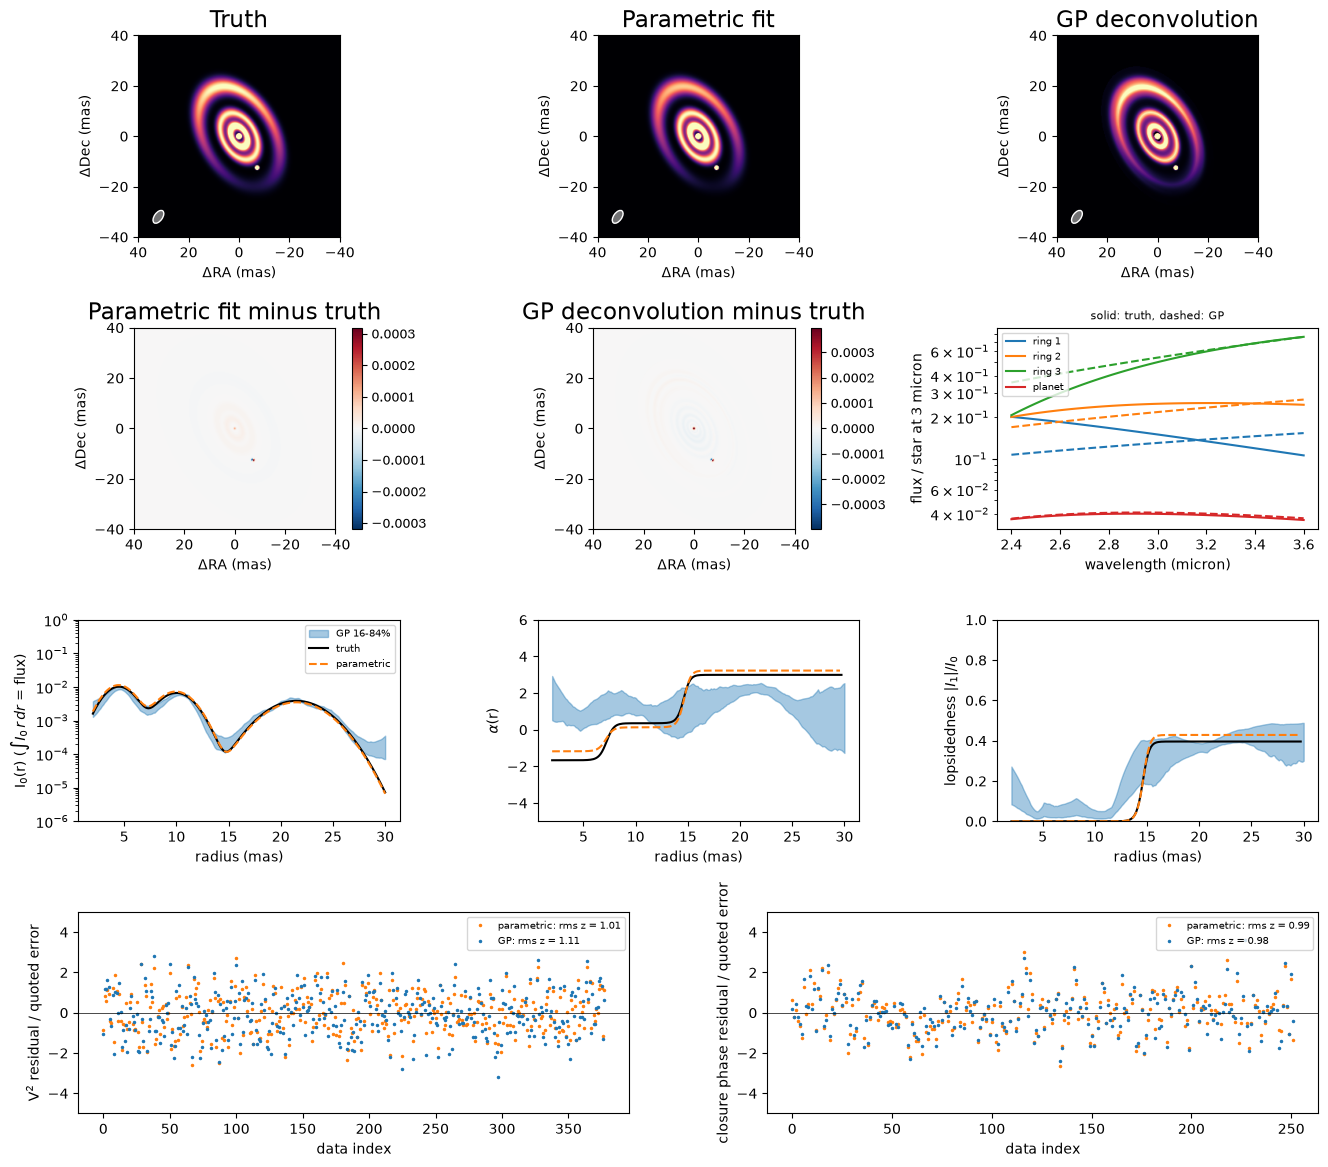

rms error of ln I0 over 2.0-29.0 mas (truth within e^-6 of its peak): GP 0.33, parametric 0.10


In [6]:
par_model, bm = par.model, beam(data)
y, err = data.flatten_data()
n_vis = np.asarray(data.vis).size
lam = np.linspace(2.4e-6, 3.6e-6, 50)
alpha_of = lambda t: float(jax.grad(lambda l: jnp.log(BlackBody(1.0, t, W0)(l)))(W0) * W0)


def truth_profile(r, p):
    """I0(r) at 3 micron, the intensity-weighted alpha(r) and the harmonic |I_1|(r).

    Each ring is exp[-(r - r_i)^2 / 2 s_i^2], as GaussianRing has it, normalized by
    sqrt(2 pi) s_i r_i so that the integral of I0 r dr is the ring's flux (exact to
    <0.1 percent here, where r_i >> s_i).
    """
    g = [p[f"f{i}"] * np.exp(-0.5 * ((r - p[f"r{i}"]) / p[f"s{i}"]) ** 2)
         / (np.sqrt(2 * np.pi) * p[f"s{i}"] * p[f"r{i}"]) for i in (1, 2, 3)]
    a = [alpha_of(p[f"t{i}"]) for i in (1, 2, 3)]
    h3 = abs(np.asarray(Harmonics(re=p["h_re"], im=p["h_im"]).image_harmonics())[1])
    tot = sum(g) + 1e-30
    return sum(g), sum(gi * ai for gi, ai in zip(g, a)) / tot, h3 * g[2] / tot


fig = plt.figure(figsize=(16, 14))
grid = fig.add_gridspec(4, 6, hspace=0.45, wspace=1.5)
models = [(truth_model, "Truth"), (par_model, "Parametric fit"), (gpm, "GP deconvolution")]
for j, (m, name) in enumerate(models):
    plot_model(m, fov_mas=FOV, npix=256, ax=fig.add_subplot(grid[0, 2 * j:2 * j + 2]),
               saturate=0.99, beam=bm, title=name)
true_image = truth_model.render(npix=256, fov_mas=FOV)
for j, (m, name) in enumerate(models[1:]):
    ax = plot_residual_map(np.asarray(m.render(npix=256, fov_mas=FOV) - true_image), FOV,
                           ax=fig.add_subplot(grid[1, 2 * j:2 * j + 2]),
                           title=f"{name} minus truth")
    cbar = ax.images[0].colorbar  # the title names the quantity; the bar's label collided with the spectra panel
    cbar.set_label("")
    cbar.ax.tick_params(labelsize=9)
ax = fig.add_subplot(grid[2, 0:2])
i_t, a_t, h_t = truth_profile(rg, truth)
i_p, a_p, h_p = truth_profile(rg, dict(par.values))
ax.fill_between(rg, *band(post_i0), color="C0", alpha=0.4, label="GP 16-84%")
ax.plot(rg, i_t, "k", label="truth")
ax.plot(rg, i_p, "C1--", label="parametric")
ax.set(yscale="log", ylim=(1e-6, 1e0), xlabel="radius (mas)", ylabel=r"I$_0$(r) ($\int I_0\,r\,dr$ = flux)")
ax.legend(fontsize=7)
ax = fig.add_subplot(grid[2, 2:4])
ax.fill_between(rg, *band(post_al), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), a_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), a_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"$\alpha$(r)", ylim=(-5, 6))
ax = fig.add_subplot(grid[2, 4:6])
ax.fill_between(rg, *band(post_h1), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), h_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), h_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"lopsidedness $|I_1|/I_0$", ylim=(0, 1))
ax = fig.add_subplot(grid[1, 4:6])
nodes, w = (np.asarray(x) for x in gpm.disk.profile.quadrature())
frac, al = w / w.sum(), np.asarray(gpm.disk.spectral_index(nodes))
# windows split at the minima of the true profile between the ring centres
cuts = []
for a, b in [(truth["r1"], truth["r2"]), (truth["r2"], truth["r3"])]:
    inside = (rg > a) & (rg < b)
    cuts.append(float(rg[inside][np.argmin(i_t[inside])]))
for i, (lo, hi) in enumerate([(0, cuts[0]), (cuts[0], cuts[1]), (cuts[1], 99)]):
    inside = (nodes >= lo) & (nodes < hi)
    f_gp = float(gpm.disk.flux) * (frac[inside, None] * (lam / W0) ** al[inside, None]).sum(0)
    t_i = BlackBody(truth[f"f{i + 1}"], truth[f"t{i + 1}"], W0)(lam)
    ax.plot(lam * 1e6, t_i, f"C{i}", label=f"ring {i + 1}")
    ax.plot(lam * 1e6, f_gp, f"C{i}--")
ax.plot(lam * 1e6, BlackBody(truth["fp"], truth["tp"], W0)(lam), "C3", label="planet")
ax.plot(lam * 1e6, BlackBody(gv["planet.flux.ratio"], gv["planet.flux.temperature"], W0)(lam), "C3--")
ax.set(xlabel="wavelength (micron)", ylabel="flux / star at 3 micron", yscale="log")
ax.set_title("solid: truth, dashed: GP", fontsize=8)
ax.legend(fontsize=7)
for col, (sl, label) in enumerate([(slice(0, n_vis), r"V$^2$"), (slice(n_vis, None), "closure phase")]):
    ax = fig.add_subplot(grid[3, 3 * col:3 * col + 3])
    for m, name, c in [(par_model, "parametric", "C1"), (gpm, "GP", "C0")]:
        z = np.asarray(data.residuals(data.model(m)))[sl] / err[sl]
        ax.plot(z, ".", ms=3, color=c, label=f"{name}: rms z = {np.sqrt(np.mean(z**2)):.2f}")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="data index", ylabel=f"{label} residual / quoted error", ylim=(-5, 5))
    ax.legend(fontsize=7, loc="upper right")
plt.show()

i_map = np.asarray(profile_alpha(flat0)[0])
near = i_t > i_t.max() * np.exp(-6)
rms_ln = lambda i: np.sqrt(np.mean((np.log(i[near]) - np.log(i_t[near])) ** 2))
print(f"rms error of ln I0 over {rg[near].min():.1f}-{rg[near].max():.1f} mas "
      f"(truth within e^-6 of its peak): GP {rms_ln(i_map):.2f}, parametric {rms_ln(i_p):.2f}")


## Summary

A non-parametric `MultipoleDisk` fits the same data as the parametric family without being told there are three rings: its profile, colour and lopsidedness are Gaussian processes, and only the planet keeps its parametric form. It reaches a $\chi^2/N$ close to that of the family that made the data, recovers the planet's position and flux, and pays for its freedom with a less accurate profile (a larger rms error of $\ln I_0$ against the truth; both are printed above). The profile's length scale is a prior choice, since the two evidences differ by only a couple of nat; structure finer than the 2 to 3 mas half-fringe is not constrained in either fit; and the Laplace $\log Z$ comparison with the parametric model is only indicative.

For real data, use the two together: the Gaussian process to find structure and propose a parametric family, and the parametric fit and its evidence to confirm and measure it. Sampling the hyperparameters with NUTS is the natural next step and is not done here.

## As a pipeline

Both fits above can be run with [`DiskPipeline`](pipeline.md), which is provisional. It fixes the order of the steps and writes a run folder that reloads without recomputing. The simulated `data` are its `load` stage. A grid over the inclination and position angle with a single ring, then a fit of that ring, is its `geometry` stage; the geometry it finds is the starting point of the parametric fit and the geometry that the Gaussian process holds. The `profile` and `compare` stages fit the model and choose among its variants. `model="rings"` adds Gaussian rings, each sharing the inclination and position angle, until the BIC stops improving, and keeps the count of least BIC; `model="gp"` (the default) fits a `RadialGP` profile with `Harmonics` of degree one and a spectral index that is itself a Gaussian process, at each length scale of a grid, and keeps the length of largest Laplace evidence. The cell below sets only the choices made in this notebook: the 6000 K blackbody star, the 3 micron reference wavelength, an outer radius of 30 mas (the default is half the field of view, which cuts through the outer ring at 21.5 mas), and the companion search, which is off by default. The length-scale grid is $\ell/\sqrt{3}$ of 0.4, 1 and 2 half-fringes of the longest baseline, about 1.4 to 2.1, 3.5 to 5.2 and 6.9 to 10.4 mas for a half-fringe of 2 to 3 mas, which brackets the 2 and 5 mas used above. Neither run samples: `posterior=True` would run NUTS with the geometry released.

The pipelines find the rings and the planet without being told how many there are or where. Their priors are the pipeline's group-invariant ones (a flux, radius and width are log-uniform, the inclination is uniform in $\cos i$, the position angle an angle vector), and each ring's colour is a power law in wavelength, which only approximates the blackbodies that made the data. So the numbers agree with the hand-written fits to within the Laplace uncertainties, not exactly. They report $\chi^2/N$ on the quoted errors as the first check of each run.

In [ ]:
from tempfile import mkdtemp

from virgil.pipeline import DiskPipeline

settings = dict(
    r_out_mas=30.0,
    star_temperature_k=6000.0,
    wavel0_m=W0,
    companion=True,
    max_rings=4,
    ell_halffringes=[0.4, 1.0, 2.0],
    quicklook_execute=False,
)
# The rings are blackbodies here, so give the rings model that colour law (the
# default, a power-law index per ring, cannot follow a blackbody across the band).
rings_res = DiskPipeline(
    data, "rings", output=f"{mkdtemp()}/rings_run", ring_colour="blackbody",
    **settings
).run()
gp_res = DiskPipeline(
    data, "gp", output=f"{mkdtemp()}/gp_run", **settings
).run()

print(rings_res.describe())
print()
print(gp_res.describe())

In [ ]:
from virgil.pipeline.disk import plot_summary

plot_summary(gp_res.model(), data, r_out_mas=30.0, r_in_mas=gp_res.summary["model"]["r_in_mas"])
plt.show()

In [ ]:
rings_s, gp_s = rings_res.summary, gp_res.summary
best_chi2 = lambda s: s["chi2"]["reduced"][s["disk"]["best"]]
print(f"chi2/N: rings {best_chi2(rings_s):.2f} (tutorial 1.01), gp {best_chi2(gp_s):.2f} (tutorial 1.14)")
print(f"inc, pa: truth ({truth['inc']}, {truth['pa']}); tutorial (50.11, 29.97); "
      f"rings ({rings_s['disk']['inc_deg']:.2f}, {rings_s['disk']['pa_deg']:.2f}); "
      f"gp ({gp_s['disk']['inc_deg']:.2f}, {gp_s['disk']['pa_deg']:.2f}); "
      f"single-ring stage ({gp_s['geometry']['inc_deg']:.2f}, {gp_s['geometry']['pa_deg']:.2f})")
best_rings = next(
    row for row in rings_s["compare"]["rows"] if row["n"] == rings_s["disk"]["n_rings"]
)
fitted = best_rings["radii"]
for i in (1, 2, 3):
    k = int(np.argmin([abs(r - truth[f"r{i}"]) for r in fitted]))
    sd = best_rings["sd"][f"r{k + 1}"] or 0.0
    print(f"ring {i}: truth r={truth[f'r{i}']:.2f}  pipeline r={fitted[k]:.2f} +- {sd:.2f} mas")
    # The rings are found within a few Laplace standard deviations of the truth.
    assert abs(fitted[k] - truth[f"r{i}"]) < 4 * sd + 0.3
assert rings_s["disk"]["n_rings"] >= 3

for name, s, tol in (("rings", rings_s, 0.1), ("gp", gp_s, 0.3)):
    planet = s["disk"]["companion"]
    assert planet is not None, name
    print(f"{name:>5} planet: dra={planet['dra_mas']:.2f}  ddec={planet['ddec_mas']:.2f}  "
          f"flux={planet['flux']:.3f}  (truth {truth['dra']}, {truth['ddec']}, {truth['fp']})")
    sd = best_rings["sd"] if name == "rings" else {}
    assert abs(planet["dra_mas"] - truth["dra"]) < 4 * (sd.get("dra") or 0.0) + tol
    assert abs(planet["ddec_mas"] - truth["ddec"]) < 4 * (sd.get("ddec") or 0.0) + tol

assert best_chi2(rings_s) < 1.3
assert best_chi2(gp_s) < 1.6
assert rings_res.checks[0].name == gp_res.checks[0].name == "chi2_reduced"
